In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import ast
from scipy.stats import chisquare

### Computing the reduced chisquared to identify upper-limits

Calculating my own chisquared values

In [26]:
def chisqr(obs_flux, synth_flux, obs_flux_err):
    """
    Calculate the chi-squared statistic.
    
    Parameters:
    obs_flux : array-like
        Observed flux points.
    synth_flux : array-like
        Synthetic flux points.
    obs_flux_err : array-like
        Observed flux errors.
        
    Returns:
    float
        The chi-squared statistic.
    """
    return np.sum(((obs_flux - synth_flux) / obs_flux_err) ** 2)


# Loading in the data
# path = '/data/misfit/benlowe/xshooter/korg_data/synths/test/test1_currentwindows/ra_1633-2814_s284/Eu_II/lowest_synth/line_4129.725/spectra/'
path = '/data/misfit/benlowe/xshooter/korg_data/synths/test/test1_currentwindows/ra_1633-2814_s284/Cr_I/lowest_synth/line_5206.023/spectra/'
test_data = [path + file for file in os.listdir(path)]

# Looping through the files and calculating chi-squared
chisqr_dicts = []
for file in test_data:
    # print(file.split('/')[-1])
    abund = file.split('/')[-1].split('_')[0]
    
    # Loading in the data
    data = pd.read_csv(file)
    obs_flux = ast.literal_eval(data['obs_flux'].to_numpy()[0])
    obs_flux_err =  ast.literal_eval(pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/synths/test/test1_currentwindows/ra_1633-2814_s284/Cr_I/obs/line_5206.023/spectra/-0.0_spec.csv')['obs_flux_err'].to_numpy()[0])
    obs_wave = ast.literal_eval(data['obs_wave'].to_numpy()[0])
    synth_flux = ast.literal_eval(data['fit_flux'].to_numpy()[0])
    
    # Taking the pixels ± 2 around the line centre
    line_range = 2 # in A
    line_center = 5206.023
    
    line_mask = (np.array(obs_wave) > (line_center - line_range)) & (np.array(obs_wave) < (line_center + line_range))
    obs_flux = np.array(obs_flux)[line_mask]
    obs_flux_err = np.array(obs_flux_err)[line_mask]
    obs_wave = np.array(obs_wave)[line_mask]
    synth_flux = np.array(synth_flux)[line_mask]
    
    # plt.figure()
    # plt.plot(obs_wave, obs_flux, label='Observed Flux', color='blue')
    # plt.plot(obs_wave, synth_flux, label='Synthetic Flux', color='red')
    
    # Calculating chi-squared
    chisqr_val = chisqr(obs_flux, synth_flux, obs_flux_err)
    print(chisqr_val)
    chisqr_dict = {'chisqr': chisqr_val, 'el_xfe': abund}
    chisqr_dicts.append(chisqr_dict)

chisqr_df = pd.DataFrame(chisqr_dicts)
chisqr_df.to_csv('/data/misfit/benlowe/xshooter/korg_data/synths/test/test1_currentwindows/ra_1633-2814_s284/Cr_I/lowest_synth/line_5206.023/5206.023_chisqrs.csv')
    

chisqr_df

2.408916661681047e-14
1.1011550004799597e-06
5.020281441208802e-06
1.1162154543895579e-05
2.0420839566785574e-05
3.218322919038606e-05
4.6977125032231314e-05
6.50024171152246e-05
8.646969562070828e-05
0.00011145720204901702
0.000140465241662049
0.00017361538786594242
0.0002111665293472209
0.0002533911706338692
0.00030057610187653086
0.000353023100546704
0.00041104966638621994
0.0004749897914048331
0.0005451947662795811
0.0006220340251223525
0.0007058960301416062
0.0007971891982065006
0.0008963428713159452
0.0010038083327231883
0.0011200598710228778
0.0012455958947600982
0.0013809400989153167
0.0015266426869336672
0.0016832816496381627
0.0018514641046871016
0.0020318276985338978
0.0022250420743131108
0.0024318104083595133
0.0026528710188833318
0.0028889990493158077
0.003141008230994075
0.0034289726567723684
0.0037162425565463713
0.004022491940343401
0.004348370859686137
0.00469491888274811
0.005077789691974943
0.005469905932165244
0.005886174547880037
0.006335700552940271
0.006804595217

,chisqr,el_xfe
0,2.408917e-14,-2.0
1,1.101155e-06,-1.99
2,5.020281e-06,-1.98
3,1.116215e-05,-1.97
4,2.042084e-05,-1.96
...,...,...
396,1.126287e+03,1.96
397,1.136213e+03,1.97
398,1.146199e+03,1.98
399,1.156239e+03,1.99


In [24]:
obs_flux_err

array([0.00550524, 0.0054665 , 0.00542839, 0.0054172 , 0.00543778,
       0.0054935 , 0.00547938, 0.00544846, 0.00548945, 0.00548792,
       0.00547815, 0.00549146, 0.00551082, 0.00547467, 0.00541294,
       0.00544106, 0.00545322, 0.00543788, 0.00543343, 0.00543765])

Checking the chisquares 

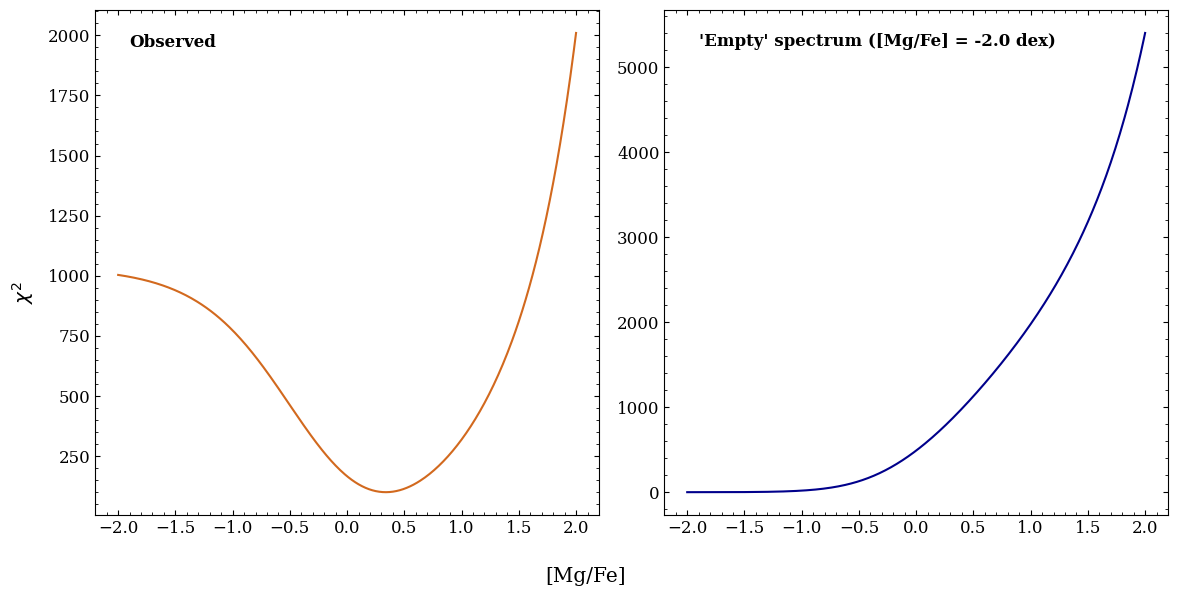

In [23]:
# Observed chisquares
chisqrs_obs_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/synths/test/ra_1633-2814_s284/Mg_I/obs/line_5167.322/5167.322_chisqrs.csv")
chisqrs_obs = chisqrs_obs_df["chisqr"].values
abund_obs = chisqrs_obs_df["el_xfe"].values

# Synthetic chisquares
chisqrs_synth_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/synths/test/ra_1633-2814_s284/Mg_I/lowest_synth/line_5167.322/5167.322_chisqrs.csv")
chisqrs_synth = chisqrs_synth_df["chisqr"].values
abund_synth = chisqrs_synth_df["el_xfe"].values

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(abund_obs, chisqrs_obs, color='chocolate', label='Observed')
ax[0].text(-1.9, 1950, "Observed", fontweight='bold')

ax[1].plot(abund_synth, chisqrs_synth, color='darkblue', label='Synthetic')
ax[1].text(-1.9, 5250, "'Empty' spectrum ([Mg/Fe] = -2.0 dex)", fontweight='bold')

fig.supxlabel("[Mg/Fe]")
fig.supylabel(r"$\chi^2$")
plt.tight_layout()
# plt.ylim(40, 75)